In [ ]:
import pandas as pd

df = pd.read_csv('Advertising - Advertising.csv')

# Remove unnecessary index column
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Standardize column names to match the expected casing in subsequent cells
df.columns = df.columns.str.capitalize()
# Specific fix for TV which should remain capitalized as 'TV'
df = df.rename(columns={'Tv': 'TV'})

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset Shape: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [ ]:
print("First 10 Records:")
display(df.head(10))

print("Last 10 Records:")
display(df.tail(10))

First 10 Records:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
5,8.7,48.9,75.0,7.2
6,57.5,32.8,23.5,11.8
7,120.2,19.6,11.6,13.2
8,8.6,2.1,1.0,4.8
9,199.8,2.6,21.2,10.6


Last 10 Records:


,TV,Radio,Newspaper,Sales
190,39.5,41.1,5.8,10.8
191,75.5,10.8,6.0,9.9
192,17.2,4.1,31.6,5.9
193,166.8,42.0,3.6,19.6
194,149.7,35.6,6.0,17.3
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


In [ ]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 200
Total Columns: 4


In [ ]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

print("Independent Variables (X):")
print(X.columns.tolist())

print("\nDependent Variable (y):")
print(y.name)

Independent Variables (X):
['TV', 'Radio', 'Newspaper']

Dependent Variable (y):
Sales


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [ ]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 0


In [ ]:
print("Minimum Values:\n", df.min())

print("\nMaximum Values:\n", df.max())

print("\nMean Values:\n", df.mean())

print("\nStandard Deviation:\n", df.std())

Minimum Values:
 TV           0.7
Radio        0.0
Newspaper    0.3
Sales        1.6
dtype: float64

Maximum Values:
 TV           296.4
Radio         49.6
Newspaper    114.0
Sales         27.0
dtype: float64

Mean Values:
 TV           147.0425
Radio         23.2640
Newspaper     30.5540
Sales         14.0225
dtype: float64

Standard Deviation:
 TV           85.854236
Radio        14.846809
Newspaper    21.778621
Sales         5.217457
dtype: float64


In [ ]:
for column in df.columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]

    print(column, ":", len(outliers), "outliers")

TV : 0 outliers
Radio : 0 outliers
Newspaper : 2 outliers
Sales : 0 outliers


In [ ]:
print("Missing values before preprocessing:")
print(df.isnull().sum())

df = df.dropna()

print("\nMissing values after preprocessing:")
print(df.isnull().sum())

Missing values before preprocessing:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Missing values after preprocessing:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 160
Testing samples: 40


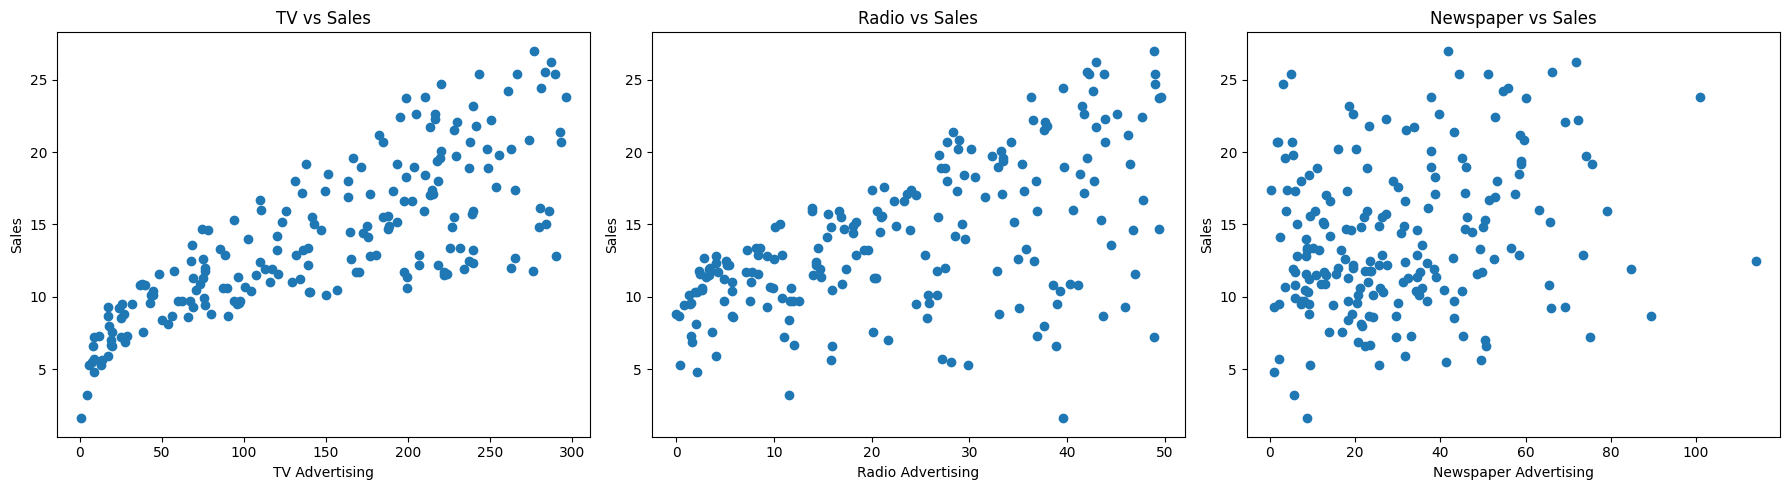

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 5))

# TV vs Sales
plt.subplot(1, 3, 1)
plt.scatter(df['TV'], df['Sales'])
plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('TV vs Sales')

# Radio vs Sales
plt.subplot(1, 3, 2)
plt.scatter(df['Radio'], df['Sales'])
plt.xlabel('Radio Advertising')
plt.ylabel('Sales')
plt.title('Radio vs Sales')

# Newspaper vs Sales
plt.subplot(1, 3, 3)
plt.scatter(df['Newspaper'], df['Sales'])
plt.xlabel('Newspaper Advertising')
plt.ylabel('Sales')
plt.title('Newspaper vs Sales')

plt.tight_layout()
plt.show()

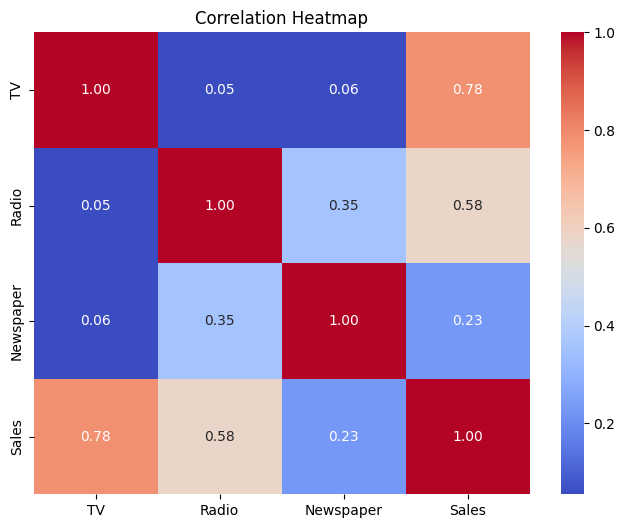

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

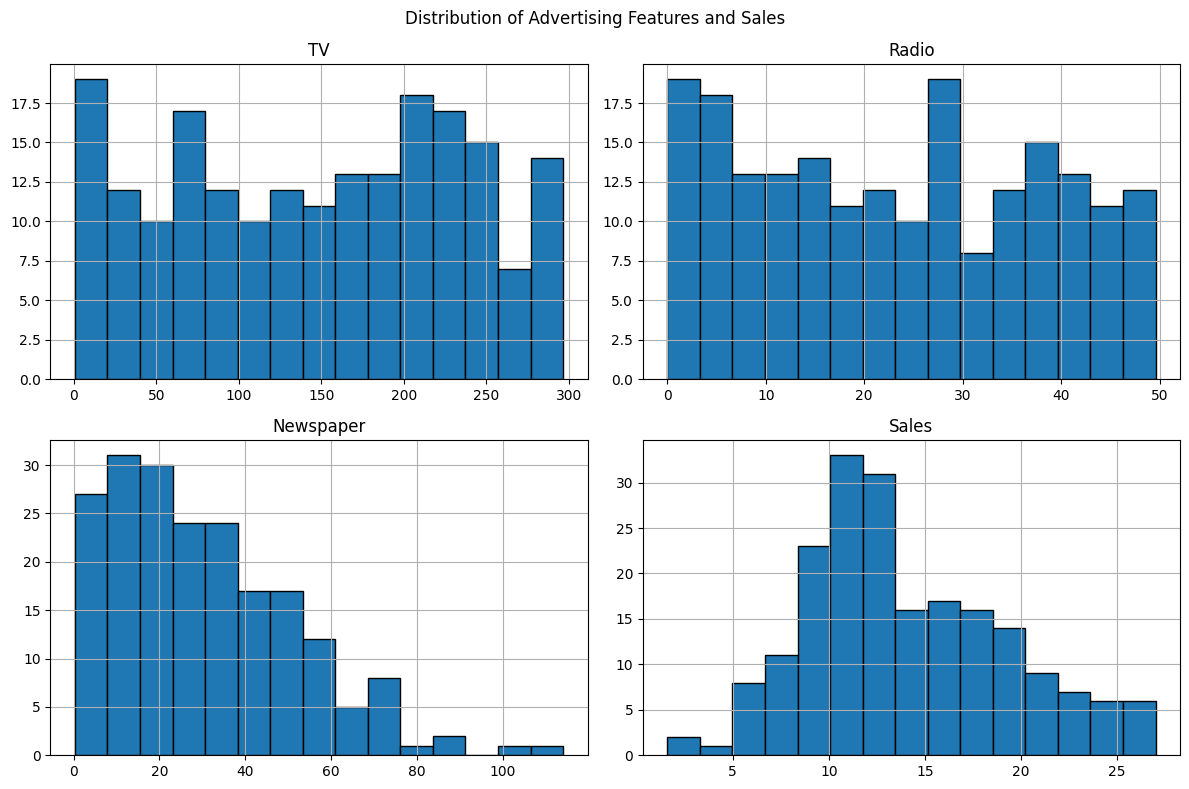

In [ ]:
import matplotlib.pyplot as plt

df.hist(figsize=(12, 8), bins=15, edgecolor='black')

plt.suptitle('Distribution of Advertising Features and Sales')
plt.tight_layout()
plt.show()

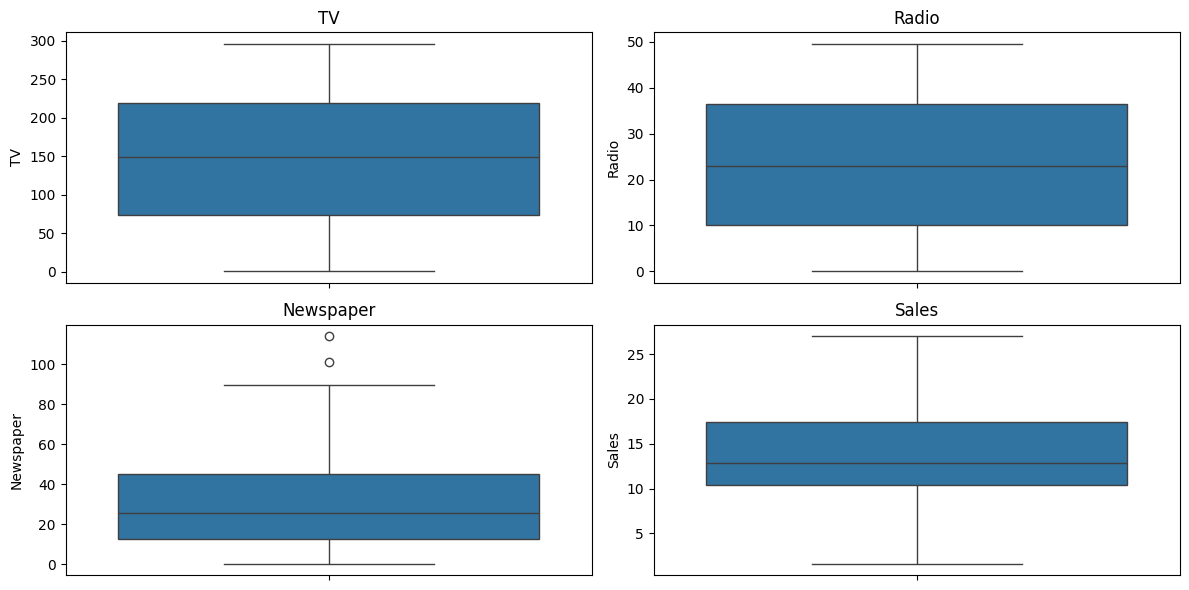

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

for i, column in enumerate(df.columns):
    if column == 'Sales_Category':
        continue
    plt.subplot(2, 2, i+1)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

In [ ]:
print("Correlation with Sales:")
print(df.corr()['Sales'].sort_values(ascending=False))

print("\nFeature Variation:")
print(df.std().sort_values(ascending=False))

print("\nCorrelation between TV and Radio:")
print(df['TV'].corr(df['Radio']))

Correlation with Sales:
Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64

Feature Variation:
TV           85.854236
Newspaper    21.778621
Radio        14.846809
Sales         5.217457
dtype: float64

Correlation between TV and Radio:
0.054808664465830034


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Independent and dependent variables
X = df[['TV']]
y = df['Sales']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])

Intercept: 7.119638430592953
Coefficient: 0.046529733705443346


In [ ]:
print(
    f"Sales = {simple_model.intercept_:.4f} "
    f"+ ({simple_model.coef_[0]:.4f} * TV)"
)

Sales = 7.1196 + (0.0465 * TV)


In [ ]:
y_pred_simple = simple_model.predict(X_test)

results = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred_simple
})

display(results.head(10))

,Actual Sales,Predicted Sales
0,16.9,14.717944
1,22.4,16.211548
2,21.4,20.748197
3,7.3,7.664036
4,24.7,17.370139
5,12.6,10.614021
6,22.3,17.207285
7,8.4,9.446125
8,11.5,17.467851
9,14.9,15.266995


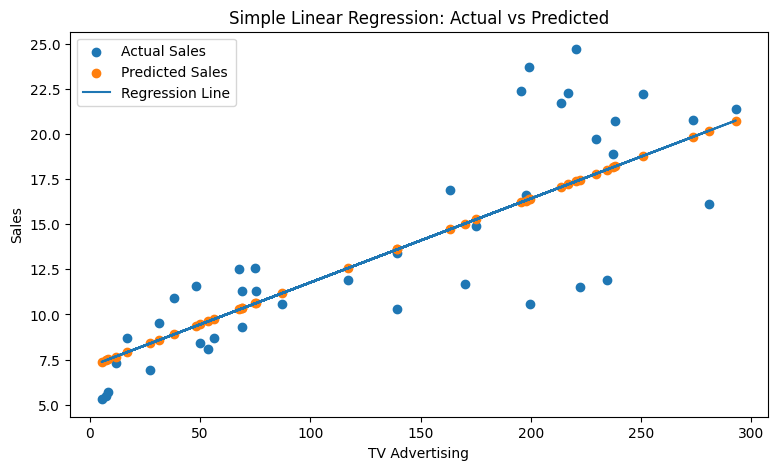

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(X_test['TV'], y_test, label='Actual Sales')
plt.scatter(X_test['TV'], y_pred_simple, label='Predicted Sales')

plt.plot(
    X_test['TV'],
    y_pred_simple,
    label='Regression Line'
)

plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('Simple Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()

In [ ]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

print("Multiple Linear Regression trained successfully!")

Multiple Linear Regression trained successfully!


In [ ]:
print("Intercept:", multiple_model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': multiple_model.coef_
})

display(coefficients)

Intercept: 2.979067338122629


,Feature,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


In [ ]:
y_pred_multiple = multiple_model.predict(X_test)

results_multiple = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred_multiple
})

display(results_multiple.head(10))

,Actual Sales,Predicted Sales
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373
5,12.6,13.105592
6,22.3,21.057192
7,8.4,7.461010
8,11.5,13.606346
9,14.9,15.155070


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensure the proper splits for continuous sales targets are established
X_simple = df[['TV']]
X_multiple = df[['TV', 'Radio', 'Newspaper']]
y_continuous = df['Sales']

# Split continuous data
X_train_s, X_test_s, y_train_c, y_test_c = train_test_split(X_simple, y_continuous, test_size=0.2, random_state=42)
X_train_m, X_test_m, _, _ = train_test_split(X_multiple, y_continuous, test_size=0.2, random_state=42)

# Train models
simple_model = LinearRegression().fit(X_train_s, y_train_c)
multiple_model = LinearRegression().fit(X_train_m, y_train_c)

# Generate predictions
y_pred_simple = simple_model.predict(X_test_s)
y_pred_multiple = multiple_model.predict(X_test_m)

def evaluate_model(y_actual, y_predicted, model_name):
    mae = mean_absolute_error(y_actual, y_predicted)
    mse = mean_squared_error(y_actual, y_predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_predicted)

    return {
        'Model': model_name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

simple_results = evaluate_model(
    y_test_c, y_pred_simple, 'Simple Linear Regression'
)

multiple_results = evaluate_model(
    y_test_c, y_pred_multiple, 'Multiple Linear Regression'
)

comparison = pd.DataFrame([
    simple_results,
    multiple_results
])

display(comparison)

,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,2.444420,10.204654,3.194472,0.676695
1,Multiple Linear Regression,1.460757,3.174097,1.781600,0.899438


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

In [ ]:
X = df[['TV']]
y = df['Sales']

# Degree 2 Polynomial Regression
poly2_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly2_model.fit(X, y)

# Degree 3 Polynomial Regression
poly3_model = make_pipeline(
    PolynomialFeatures(degree=3),
    LinearRegression()
)

poly3_model.fit(X, y)

print("Degree 2 and Degree 3 models trained successfully!")

Degree 2 and Degree 3 models trained successfully!


In [ ]:
y_pred_poly2 = poly2_model.predict(X)
y_pred_poly3 = poly3_model.predict(X)

print("Degree 2 Predictions:")
print(y_pred_poly2[:10])

print("\nDegree 3 Predictions:")
print(y_pred_poly3[:10])

Degree 2 Predictions:
[17.9668317   8.97186747  7.2508381  14.73338271 16.0376302   6.69415125
  9.75553418 13.21023682  6.68754311 16.82055365]

Degree 3 Predictions:
[17.70813714  9.13630928  6.98835427 14.73235213 15.84432306  6.23559162
 10.02879647 13.42481179  6.22648103 16.54820194]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


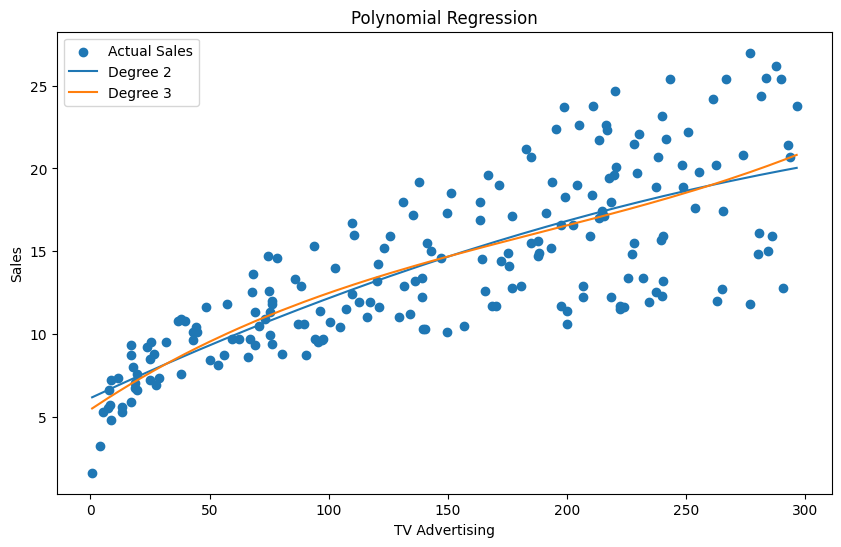

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(X['TV'], y, label='Actual Sales')

# Sort values for smooth curves
X_sorted = np.sort(X.values, axis=0)

plt.plot(
    X_sorted,
    poly2_model.predict(X_sorted),
    label='Degree 2'
)

plt.plot(
    X_sorted,
    poly3_model.predict(X_sorted),
    label='Degree 3'
)

plt.xlabel('TV Advertising')
plt.ylabel('Sales')
plt.title('Polynomial Regression')
plt.legend()
plt.show()

In [ ]:
poly2_results = evaluate_model(
    y, y_pred_poly2, 'Polynomial Degree 2'
)

poly3_results = evaluate_model(
    y, y_pred_poly3, 'Polynomial Degree 3'
)

poly_comparison = pd.DataFrame([
    poly2_results,
    poly3_results
])

display(poly_comparison)

,Model,MAE,MSE,RMSE,R2 Score
0,Polynomial Degree 2,2.557879,10.318663,3.212268,0.619037
1,Polynomial Degree 3,2.544826,10.238366,3.199745,0.622002


In [ ]:
df['Sales_Category'] = (df['Sales'] >= 15).astype(int)

print("Sales Category Created Successfully!")

display(df[['Sales', 'Sales_Category']].head(10))

Sales Category Created Successfully!


,Sales,Sales_Category
0,22.1,1
1,10.4,0
2,9.3,0
3,18.5,1
4,12.9,0
5,7.2,0
6,11.8,0
7,13.2,0
8,4.8,0
9,10.6,0


Low Sales (0): 123
High Sales (1): 77


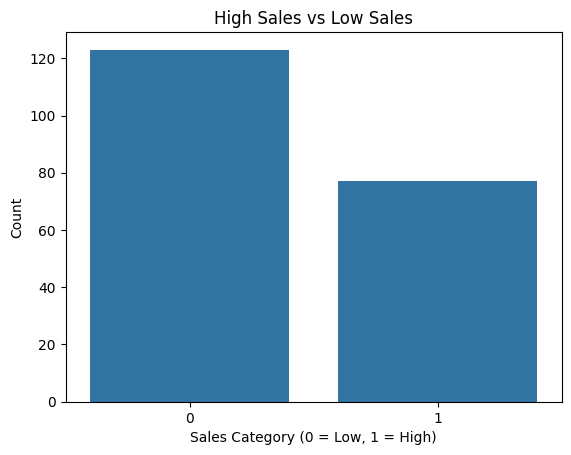

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure Sales_Category is created
if 'Sales_Category' not in df.columns:
    df['Sales_Category'] = (df['Sales'] >= 15).astype(int)

category_counts = df['Sales_Category'].value_counts()

print("Low Sales (0):", category_counts.get(0, 0))
print("High Sales (1):", category_counts.get(1, 0))

sns.countplot(x='Sales_Category', data=df)

plt.title('High Sales vs Low Sales')
plt.xlabel('Sales Category (0 = Low, 1 = High)')
plt.ylabel('Count')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Ensure Sales_Category is created
if 'Sales_Category' not in df.columns:
    df['Sales_Category'] = (df['Sales'] >= 15).astype(int)

X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales_Category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 160
Testing Samples: 40


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [ ]:
y_pred_logistic = logistic_model.predict(X_test)

results_logistic = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_pred_logistic
})

display(results_logistic.head(15))

,Actual Category,Predicted Category
0,0,0
1,0,0
2,1,1
3,0,0
4,1,1
5,0,0
6,1,0
7,0,0
8,1,1
9,1,1


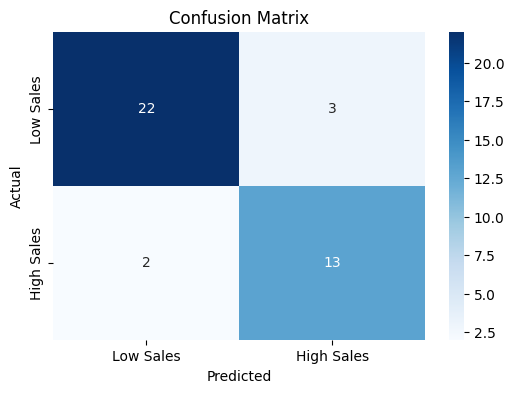

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Corrected fallback check to auto-generate variables if they are missing in the session
if 'y_test' not in globals() or 'y_pred_logistic' not in globals():
    if 'Sales_Category' not in df.columns:
        df['Sales_Category'] = (df['Sales'] >= 15).astype(int)
    X_cls = df[['TV', 'Radio', 'Newspaper']]
    y_cls = df['Sales_Category']
    X_train_c, X_test_c, y_train_c, y_test = train_test_split(
        X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
    )
    logistic_model = make_pipeline(StandardScaler(), LogisticRegression())
    logistic_model.fit(X_train_c, y_train_c)
    y_pred_logistic = logistic_model.predict(X_test_c)

cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low Sales', 'High Sales'],
    yticklabels=['Low Sales', 'High Sales']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Corrected fallback check to auto-generate variables if they are missing in the session
if 'y_test' not in globals() or 'y_pred_logistic' not in globals():
    if 'Sales_Category' not in df.columns:
        df['Sales_Category'] = (df['Sales'] >= 15).astype(int)
    X_cls = df[['TV', 'Radio', 'Newspaper']]
    y_cls = df['Sales_Category']
    X_train_c, X_test_c, y_train_c, y_test = train_test_split(
        X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
    )
    logistic_model = make_pipeline(StandardScaler(), LogisticRegression())
    logistic_model.fit(X_train_c, y_train_c)
    y_pred_logistic = logistic_model.predict(X_test_c)

print("Accuracy:", accuracy_score(y_test, y_pred_logistic))
print("Precision:", precision_score(y_test, y_pred_logistic, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_logistic, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_logistic, zero_division=0))

Accuracy: 0.875
Precision: 0.8125
Recall: 0.8666666666666667
F1 Score: 0.8387096774193549


In [ ]:
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Corrected fallback check to auto-generate variables if they are missing in the session
if 'y_test' not in globals() or 'y_pred_logistic' not in globals():
    if 'Sales_Category' not in df.columns:
        df['Sales_Category'] = (df['Sales'] >= 15).astype(int)
    X_cls = df[['TV', 'Radio', 'Newspaper']]
    y_cls = df['Sales_Category']
    X_train_c, X_test_c, y_train_c, y_test = train_test_split(
        X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
    )
    logistic_model = make_pipeline(StandardScaler(), LogisticRegression())
    logistic_model.fit(X_train_c, y_train_c)
    y_pred_logistic = logistic_model.predict(X_test_c)

print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=['Low Sales', 'High Sales'],
    zero_division=0
))

              precision    recall  f1-score   support

   Low Sales       0.92      0.88      0.90        25
  High Sales       0.81      0.87      0.84        15

    accuracy                           0.88        40
   macro avg       0.86      0.87      0.87        40
weighted avg       0.88      0.88      0.88        40



1. Compare Linear Regression, Polynomial Regression and Logistic Regression.

* Linear Regression predicts continuous numerical values using a straight-line relationship.
* Polynomial Regression predicts continuous values by fitting curved relationships using polynomial features.
* Logistic Regression predicts categorical outcomes such as High Sales and Low Sales.

2. Which model is suitable for predicting continuous sales values?

Linear Regression and Polynomial Regression are suitable for predicting continuous sales values. The better model depends on its evaluation metrics and performance on unseen data.

3. Which model is suitable for predicting High Sales or Low Sales?

Logistic Regression is suitable because it performs classification and predicts whether sales belong to the High or Low category.

4. Which advertising medium should a company prioritize?

Based on the Advertising dataset, TV advertising has the strongest positive correlation with sales. Therefore, a company should consider prioritizing TV advertising.

5. Is newspaper advertising expenditure useful for predicting sales?

Newspaper advertising has a relatively weak correlation with sales. Therefore, it may provide limited predictive information compared to TV and Radio advertising.

6. Can increasing advertising expenditure guarantee higher sales?

No. Increasing advertising expenditure does not guarantee higher sales because sales also depend on product quality, pricing, competition, customer preferences and market conditions.

7. What are the limitations of your developed models?

1. The models use only three advertising features.
2. External factors affecting sales are not considered.
3. The dataset contains only 200 observations.
4. Predictions may not always be accurate for unseen data.
5. Logistic Regression depends on the selected sales threshold.

8. Suggest two ways to improve the models.

1. Collect more data and include additional features such as product pricing, customer demographics and market trends.
2. Perform hyperparameter tuning, feature selection and cross-validation to improve model performance.